In [1]:
'''Evaluate models for bias and fairness by analyzing disparate impact metrics and fairness constraints, ensuring the admissions model does not unintentionally favor or disadvantage any demographic group.'''

'Evaluate models for bias and fairness by analyzing disparate impact metrics and fairness constraints, ensuring the admissions model does not unintentionally favor or disadvantage any demographic group.'

In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [3]:
# load dataset and create binary target
df = pd.read_csv('Adm.csv')
df['admitted'] = (df['Chance of Admit'] >= 0.7).astype(int)
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['admitted']
groups = df['region']
df[['GRE Score', 'TOEFL Score', 'CGPA', 'region', 'admitted']].head()

,GRE Score,TOEFL Score,CGPA,region,admitted
0,337,118,9.65,East,1
1,324,107,8.87,South,1
2,316,104,8.00,West,0
3,322,110,8.67,North,1
4,314,103,8.21,North,0


In [4]:
# split data into train and test sets
X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, groups, test_size=0.25, random_state=42, stratify=y
)

In [5]:
# train baseline logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print('accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.916
              precision    recall  f1-score   support

           0       0.92      0.88      0.90       107
           1       0.91      0.94      0.93       143

    accuracy                           0.92       250
   macro avg       0.92      0.91      0.91       250
weighted avg       0.92      0.92      0.92       250



In [6]:
# calculate baseline fairness and disparate impact metrics
results = pd.DataFrame({'region': g_test, 'actual': y_test, 'pred': y_pred, 'prob': y_prob})

def get_fairness_metrics(data):
    selection_rates = data.groupby('region')['pred'].mean()
    max_rate = selection_rates.max()
    disparate_impact = selection_rates / max_rate
    true_positive_rate = data[data['actual'] == 1].groupby('region')['pred'].mean()
    return pd.DataFrame({
        'selection_rate': selection_rates,
        'disparate_impact': disparate_impact,
        'true_positive_rate': true_positive_rate
    })

baseline_metrics = get_fairness_metrics(results)
print(baseline_metrics)

           selection_rate  disparate_impact  true_positive_rate
region                                                         
Central          0.625000          0.625000            1.000000
East             0.566667          0.566667            0.850000
North            0.525000          0.525000            0.926829
Northeast        1.000000          1.000000            1.000000
South            0.621053          0.621053            0.962963
West             0.647059          0.647059            1.000000


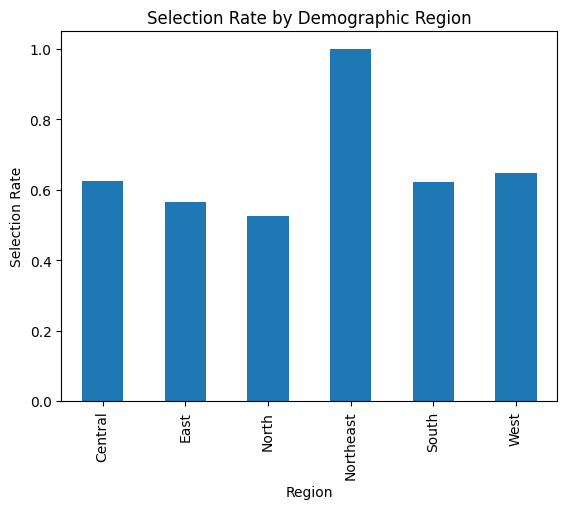

In [7]:
# plot baseline selection rate across demographic regions
plt.figure()
baseline_metrics['selection_rate'].plot(kind='bar')
plt.title('Selection Rate by Demographic Region')
plt.ylabel('Selection Rate')
plt.xlabel('Region')
plt.show()

In [8]:
# apply fairness constraints using demographic threshold tuning
target_rate = results['pred'].mean()
results_constrained = results.copy()

for region in results['region'].unique():
    mask = results['region'] == region
    probs = results.loc[mask, 'prob']
    threshold = np.quantile(probs, 1.0 - target_rate)
    results_constrained.loc[mask, 'pred'] = (probs >= threshold).astype(int)

constrained_metrics = get_fairness_metrics(results_constrained)
print(constrained_metrics)
print('constrained accuracy:', accuracy_score(results_constrained['actual'], results_constrained['pred']))

           selection_rate  disparate_impact  true_positive_rate
region                                                         
Central          0.625000          0.937500            1.000000
East             0.600000          0.900000            0.900000
North            0.587500          0.881250            1.000000
Northeast        0.666667          1.000000            0.666667
South            0.589474          0.884211            0.962963
West             0.588235          0.882353            0.904762
constrained accuracy: 0.924


<Figure size 640x480 with 0 Axes>

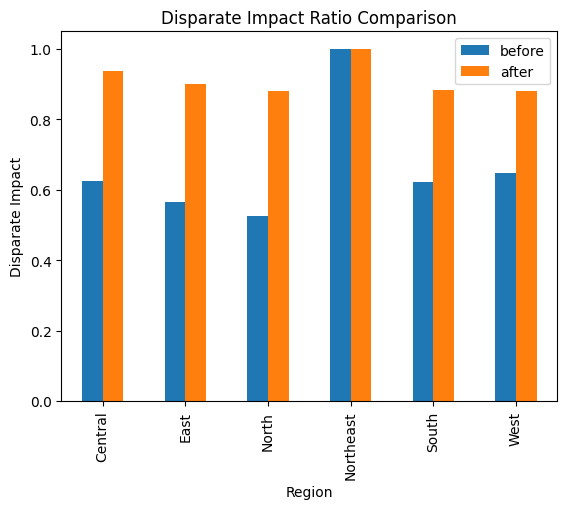

In [9]:
# plot disparate impact comparison before and after fairness constraints
comparison = pd.DataFrame({
    'before': baseline_metrics['disparate_impact'],
    'after': constrained_metrics['disparate_impact']
})
plt.figure()
comparison.plot(kind='bar')
plt.title('Disparate Impact Ratio Comparison')
plt.ylabel('Disparate Impact')
plt.xlabel('Region')
plt.show()